# Waste classification with Xception: data, results and error analysis

This notebook walks through the project end to end, using the modules in `src/`:

1. **Dataset**: class balance and examples
2. **Model**: frozen Xception backbone + softmax head
3. **Training**: learning curves of our training run
4. **Evaluation**: accuracy, per-class metrics, confusion matrix
5. **Error analysis**: which classes get confused, and why
6. **Inference**: predictions on new images

Training itself is done from the command line (`python -m src.train`), since it takes several hours on a CPU.

In [1]:
import os
import sys
from pathlib import Path

# Make the src/ package importable from the notebooks/ folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from src.config import CLASS_NAMES, DATA_DIR, IMAGE_SIZE, RESULTS_DIR
from src.data import list_images, make_generator, split_dataset
from src.model import build_model, load_trained_model
from src.predict import predict_image

sns.set_theme(style="whitegrid")
print("Dataset folder:", DATA_DIR)

Dataset folder: data/garbage_classification


## 1. Dataset

[Garbage Classification (12 classes)](https://www.kaggle.com/datasets/mostafaabla/garbage-classification): one folder per class. Download instructions are in `data/README.md`.

15515 images, 12 classes


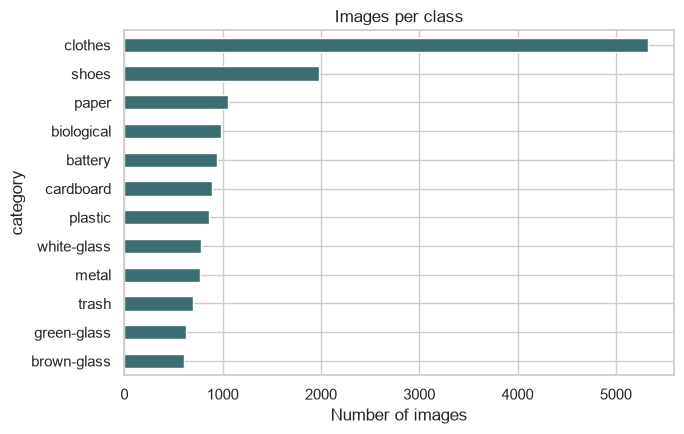

Imbalance ratio (largest / smallest class): 8.8


In [2]:
df = list_images()
counts = df["category"].value_counts()
print(f"{len(df)} images, {df['category'].nunique()} classes")

ax = counts.plot.barh(figsize=(7, 4.5), color="#3c6e71")
ax.invert_yaxis()
ax.set_xlabel("Number of images")
ax.set_title("Images per class")
plt.tight_layout()
plt.show()

print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f}")

The dataset is strongly imbalanced: *clothes* alone is about a third of the images. This is why we look at the **macro-averaged** F1 score (every class counts equally) and not only at accuracy.

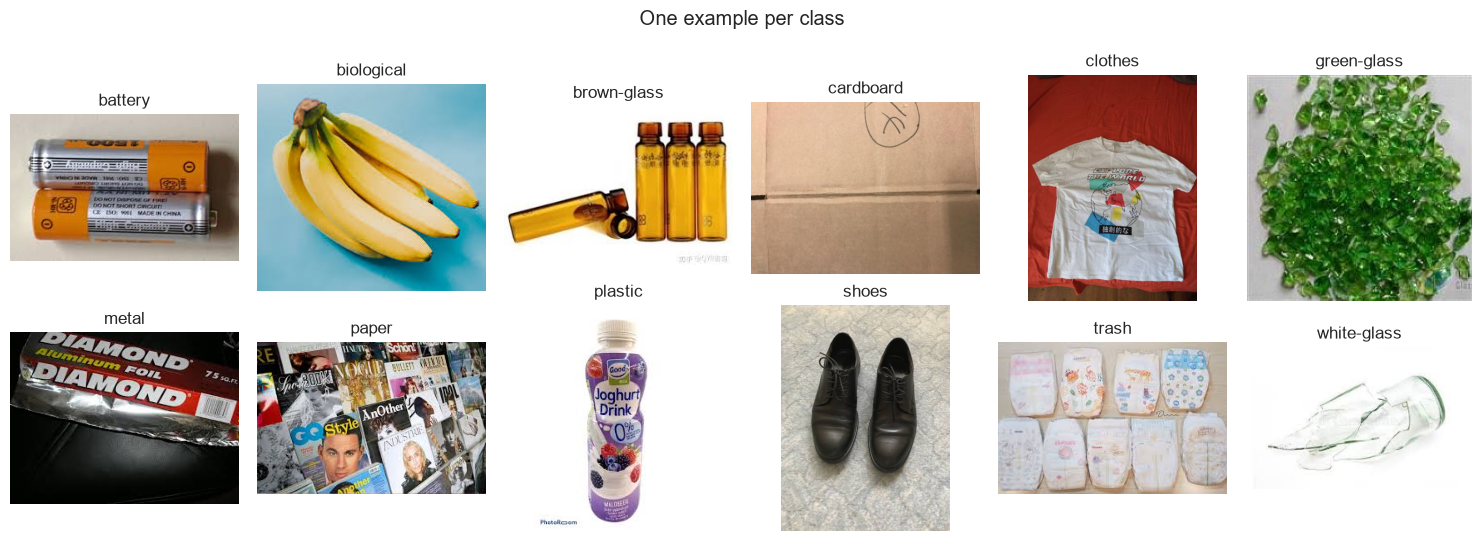

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, class_name in zip(axes.flat, CLASS_NAMES):
    filename = df.loc[df["category"] == class_name, "filename"].iloc[0]
    ax.imshow(Image.open(DATA_DIR / filename).convert("RGB"))
    ax.set_title(class_name)
    ax.axis("off")
plt.suptitle("One example per class")
plt.tight_layout()
plt.show()

In [4]:
train_df, val_df, test_df = split_dataset(df)
pd.DataFrame({
    "split": ["train", "validation", "test"],
    "images": [len(train_df), len(val_df), len(test_df)],
    "share": [f"{len(x) / len(df):.0%}" for x in (train_df, val_df, test_df)],
})

,split,images,share
0,train,12412,80%
1,validation,1551,10%
2,test,1552,10%


## 2. Model

Transfer learning: Xception pre-trained on ImageNet is kept **frozen** and used as a feature extractor (2048 features per image after global average pooling). Only the final softmax layer is trained.

In [5]:
model = build_model(weights=None)  # architecture only, the weights are loaded later
model.summary()

trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Trainable parameters: {trainable:,} / {model.count_params():,} "
      f"({trainable / model.count_params():.2%})")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception_preprocessing (Lambda) │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 10, 10, 2048)   │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │        24,588 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,886,068 (79.67 MB)

 Trainable params: 24,588 (96.05 KB)

 Non-trainable params: 20,861,480 (79.58 MB)

Trainable parameters: 24,588 / 20,886,068 (0.12%)


## 3. Training

Our training run (Adam, batch size 64, data augmentation, early stopping on validation accuracy with patience 2). The history is saved in `results/training_history.csv`.

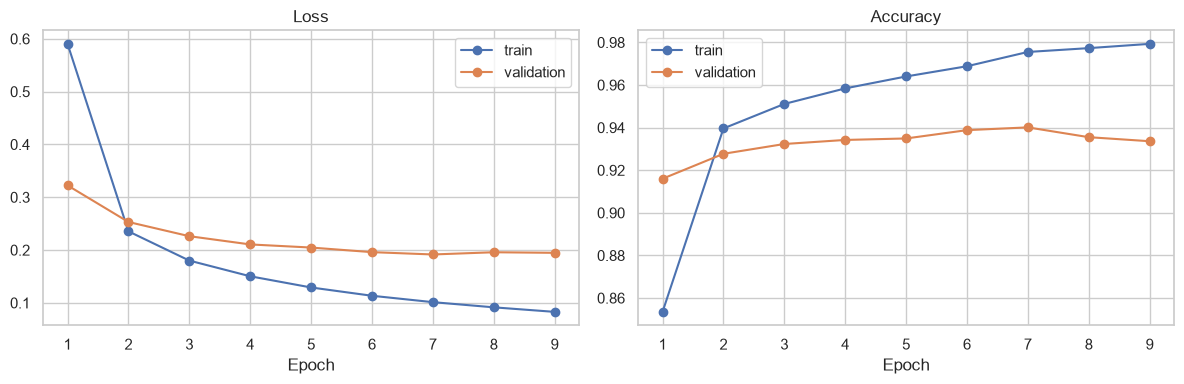

Best validation accuracy: 94.01% at epoch 7 (weights restored by early stopping)


In [6]:
history = pd.read_csv(RESULTS_DIR / "training_history.csv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history["epoch"], history["loss"], "o-", label="train")
ax1.plot(history["epoch"], history["val_loss"], "o-", label="validation")
ax1.set(title="Loss", xlabel="Epoch")
ax1.legend()
ax2.plot(history["epoch"], history["categorical_accuracy"], "o-", label="train")
ax2.plot(history["epoch"], history["val_categorical_accuracy"], "o-", label="validation")
ax2.set(title="Accuracy", xlabel="Epoch")
ax2.legend()
plt.tight_layout()
plt.show()

best = history.loc[history["val_categorical_accuracy"].idxmax()]
print(f"Best validation accuracy: {best['val_categorical_accuracy']:.2%} at epoch {int(best['epoch'])} "
      "(weights restored by early stopping)")

The validation loss stops improving after ~6 epochs while the training loss keeps decreasing: early stopping ends training before the model starts to overfit.

On the test set of this run (1,552 images), the model reached **95.81% accuracy** (see `results/classification_report_training_run.txt`).

## 4. Evaluation

We now reload the trained model and evaluate it on the test split produced by `src/data.py`.

> **Note.** This split is stratified and seeded so that it is reproducible, but it is not the same random split as the original training run. Some of these test images were therefore seen during training, so the accuracy below is slightly optimistic. The reference figure remains the 95.81% of the training run; this section is mainly used to study *which* errors the model makes.

In [7]:
model = load_trained_model()
test_gen = make_generator(test_df, shuffle=False)

probabilities = model.predict(test_gen, verbose=0)
y_pred = probabilities.argmax(axis=1)
y_true = test_gen.classes

print(f"Accuracy: {accuracy_score(y_true, y_pred):.2%} on {len(y_true)} images\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

Found 1552 validated image filenames belonging to 12 classes.


Accuracy: 97.87% on 1552 images

              precision    recall  f1-score   support

     battery      0.969     0.989     0.979        95
  biological      1.000     1.000     1.000        99
 brown-glass      0.982     0.918     0.949        61
   cardboard      1.000     0.966     0.983        89
     clothes      0.996     0.992     0.994       533
 green-glass      0.939     0.984     0.961        63
       metal      0.973     0.935     0.954        77
       paper      0.945     0.990     0.967       105
     plastic      0.974     0.884     0.927        86
       shoes      0.980     1.000     0.990       198
       trash      0.971     0.986     0.978        69
 white-glass      0.915     0.974     0.943        77

    accuracy                          0.979      1552
   macro avg      0.971     0.968     0.969      1552
weighted avg      0.979     0.979     0.979      1552



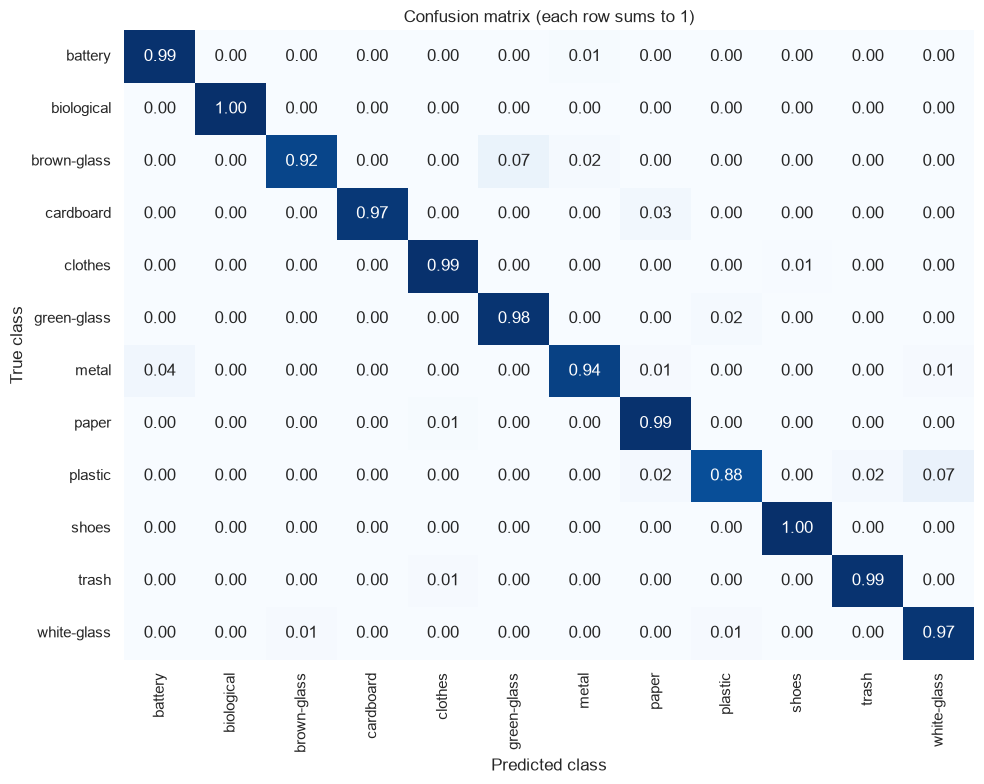

In [8]:
cm = confusion_matrix(y_true, y_pred, normalize="true")

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix (each row sums to 1)")
plt.tight_layout()
plt.show()

## 5. Error analysis

Which pairs of classes are confused the most?

In [9]:
raw_cm = confusion_matrix(y_true, y_pred)
pairs = [
    {"true": CLASS_NAMES[i], "predicted": CLASS_NAMES[j], "errors": int(raw_cm[i, j])}
    for i in range(len(CLASS_NAMES)) for j in range(len(CLASS_NAMES))
    if i != j and raw_cm[i, j] > 0
]
pd.DataFrame(pairs).sort_values("errors", ascending=False).head(8).reset_index(drop=True)

,true,predicted,errors
0,plastic,white-glass,6
1,brown-glass,green-glass,4
2,clothes,shoes,4
3,cardboard,paper,3
4,metal,battery,3
5,plastic,paper,2
6,plastic,trash,2
7,battery,metal,1


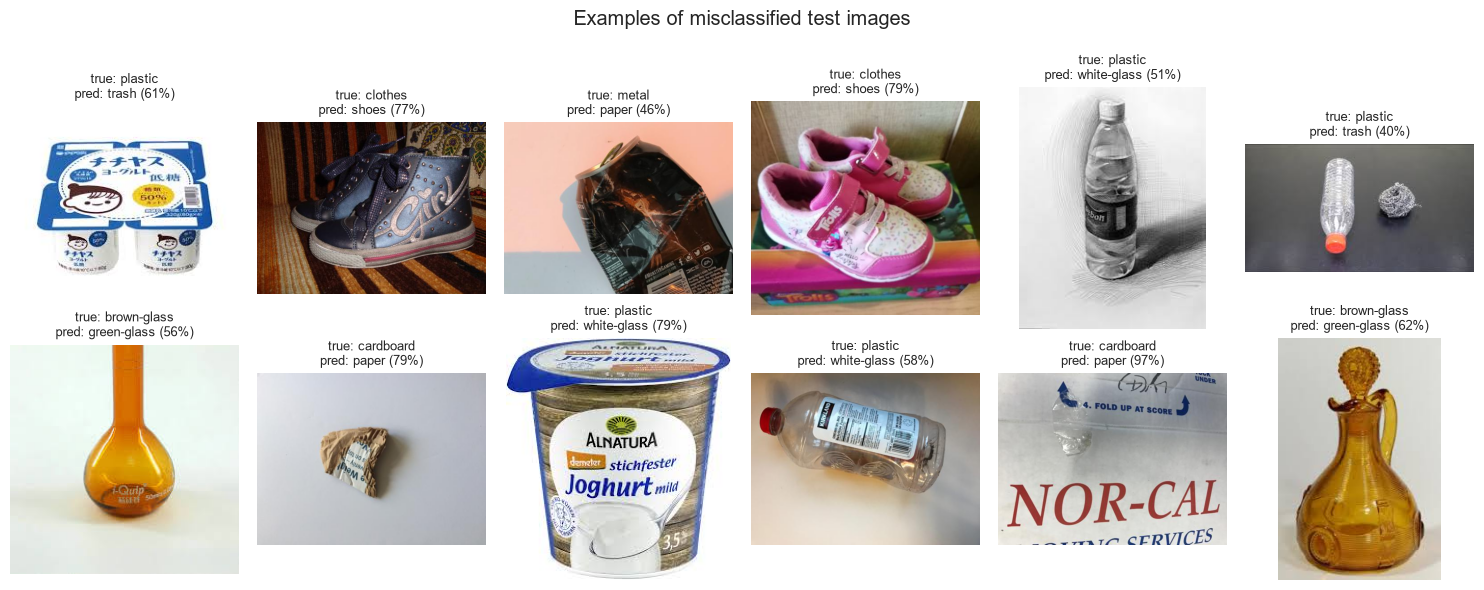

In [10]:
errors = np.flatnonzero(y_pred != y_true)
rng = np.random.default_rng(0)
shown = rng.choice(errors, size=min(12, len(errors)), replace=False)

fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for ax, i in zip(axes.flat, shown):
    ax.imshow(Image.open(DATA_DIR / test_df.loc[i, "filename"]).convert("RGB"))
    ax.set_title(f"true: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]} "
                 f"({probabilities[i].max():.0%})", fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(shown):]:
    ax.axis("off")
plt.suptitle("Examples of misclassified test images")
plt.tight_layout()
plt.show()

Most errors involve **transparent or shiny materials** (white glass, plastic, metal), whose appearance depends heavily on lighting and background, and objects that genuinely look alike (e.g. crumpled paper vs. cardboard). Some errors also come from ambiguous or mislabeled images in the dataset.

## 6. Inference on new images

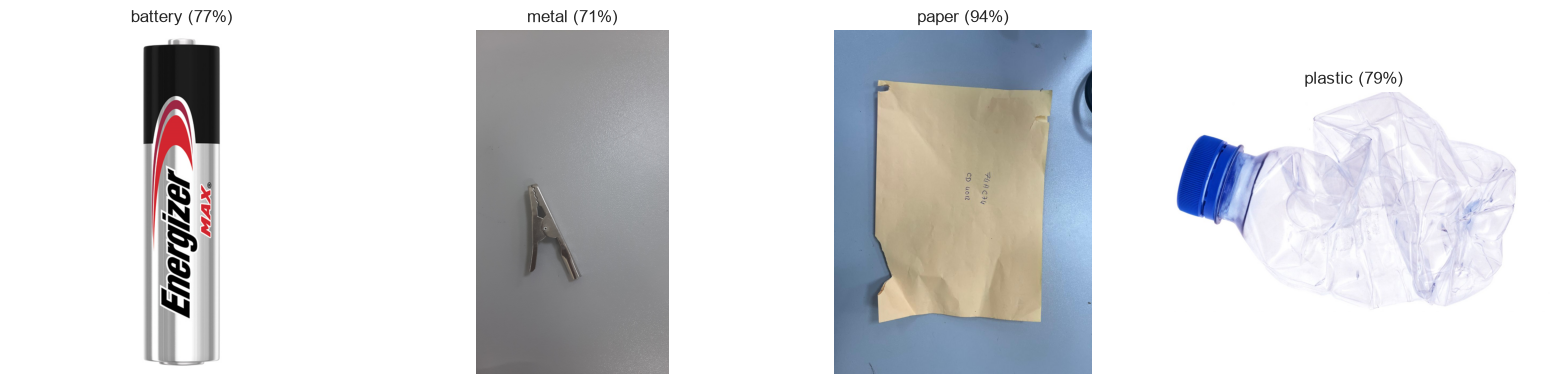

In [11]:
samples = sorted((ROOT / "data" / "samples").glob("*.jpg"))

fig, axes = plt.subplots(1, len(samples), figsize=(4 * len(samples), 4))
for ax, path in zip(np.atleast_1d(axes), samples):
    class_name, confidence = predict_image(model, path)
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"{class_name} ({confidence:.0%})")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Conclusion

- A frozen Xception backbone with a single trained layer is enough to reach **95.8% test accuracy** on 12 classes, with only ~25k trained parameters.
- The remaining errors are concentrated on glass, plastic and metal.
- Possible improvements: fine-tuning the last Xception blocks, class weights to compensate the imbalance, and more images of transparent materials taken in real conditions (the live demo shows that lighting and background matter).